Found 3028 images belonging to 4 classes.
Found 280 images belonging to 4 classes.
Found 88 images belonging to 4 classes.


/opt/conda/lib/python3.10/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


95/95 ━━━━━━━━━━━━━━━━━━━━ 297s 3s/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 25s 3s/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step
Validation Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.93      0.91       116
           1       0.78      0.82      0.80        44
           2       0.73      0.68      0.70        40
           3       0.84      0.80      0.82        80

    accuracy                           0.84       280
   macro avg       0.81      0.81      0.81       280
weighted avg       0.84      0.84      0.84       280



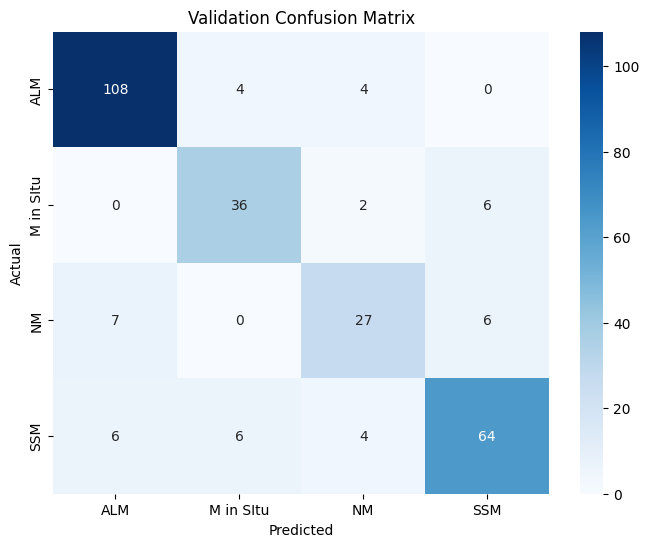

Test Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.96      0.91        26
           1       0.81      0.71      0.76        24
           2       0.93      0.72      0.81        18
           3       0.71      0.85      0.77        20

    accuracy                           0.82        88
   macro avg       0.83      0.81      0.81        88
weighted avg       0.83      0.82      0.82        88



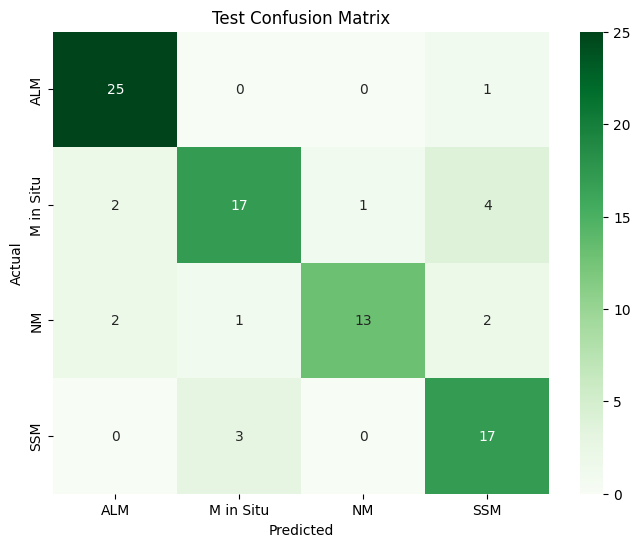

XGBoost model saved to xgboost_SAVEefficientnetb0_model.joblib
Predictions saved to test_predictions_xgb_efficientnetb0.csv


In [4]:
import numpy as np
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import pandas as pd


train_dir = '/kaggle/input/train-save'
val_dir = '/kaggle/input/valid-save'
test_dir = '/kaggle/input/test-save'


model_path = 'xgboost_SAVEefficientnetb0_model.joblib'


base_model = tf.keras.applications.EfficientNetB0(weights='imagenet', include_top=False, pooling='avg')

datagen = ImageDataGenerator(rescale=1./255)

train_generator = datagen.flow_from_directory(
    train_dir,
    target_size=(640, 640),
    batch_size=32,
    class_mode='binary',  
    shuffle=False
)

val_generator = datagen.flow_from_directory(
    val_dir,
    target_size=(640, 640),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

test_generator = datagen.flow_from_directory(
    test_dir,
    target_size=(640, 640),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

def extract_features(generator):
    features = base_model.predict(generator)
    labels = generator.classes
    return features, labels


train_features, train_labels = extract_features(train_generator)
val_features, val_labels = extract_features(val_generator)
test_features, test_labels = extract_features(test_generator)


xgb_model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='mlogloss')
xgb_model.fit(train_features, train_labels)


val_predictions = xgb_model.predict(val_features)
print("Validation Classification Report:")
print(classification_report(val_labels, val_predictions))

val_cm = confusion_matrix(val_labels, val_predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(val_cm, annot=True, fmt="d", cmap="Blues", xticklabels=train_generator.class_indices.keys(), yticklabels=train_generator.class_indices.keys())
plt.title("Validation Confusion Matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()


test_predictions = xgb_model.predict(test_features)
print("Test Classification Report:")
print(classification_report(test_labels, test_predictions))


test_cm = confusion_matrix(test_labels, test_predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(test_cm, annot=True, fmt="d", cmap="Greens", xticklabels=test_generator.class_indices.keys(), yticklabels=test_generator.class_indices.keys())
plt.title("Test Confusion Matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()


joblib.dump(xgb_model, model_path)
print(f"XGBoost model saved to {model_path}")

pred_proba = xgb_model.predict_proba(test_features)
predictions_df = pd.DataFrame({
    'Image': test_generator.filenames,
    'Prediction': test_predictions,
    'Confidence': [max(proba) for proba in pred_proba]
})
predictions_df.to_csv("test_predictions_xgb_efficientnetb0.csv", index=False)
print("Predictions saved to test_predictions_xgb_efficientnetb0.csv")


Model loaded from /kaggle/working/xgboost_SAVEefficientnetb0_model.joblib
Found 88 images belonging to 4 classes.


/opt/conda/lib/python3.10/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


3/3 ━━━━━━━━━━━━━━━━━━━━ 14s 3s/step 
Test Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.96      0.91        26
           1       0.81      0.71      0.76        24
           2       0.93      0.72      0.81        18
           3       0.71      0.85      0.77        20

    accuracy                           0.82        88
   macro avg       0.83      0.81      0.81        88
weighted avg       0.83      0.82      0.82        88



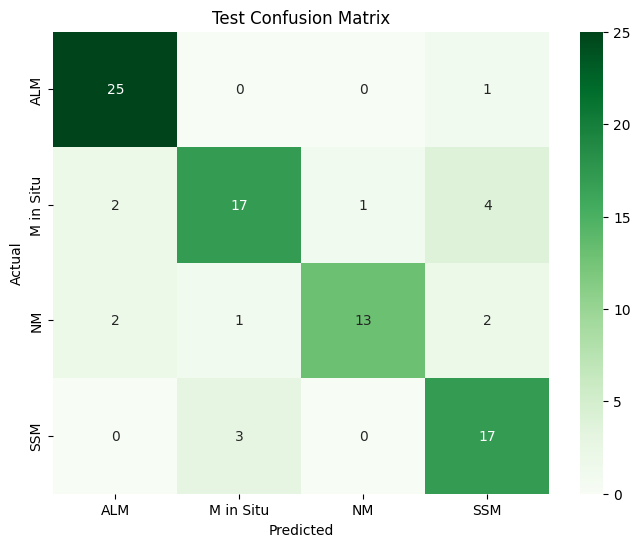

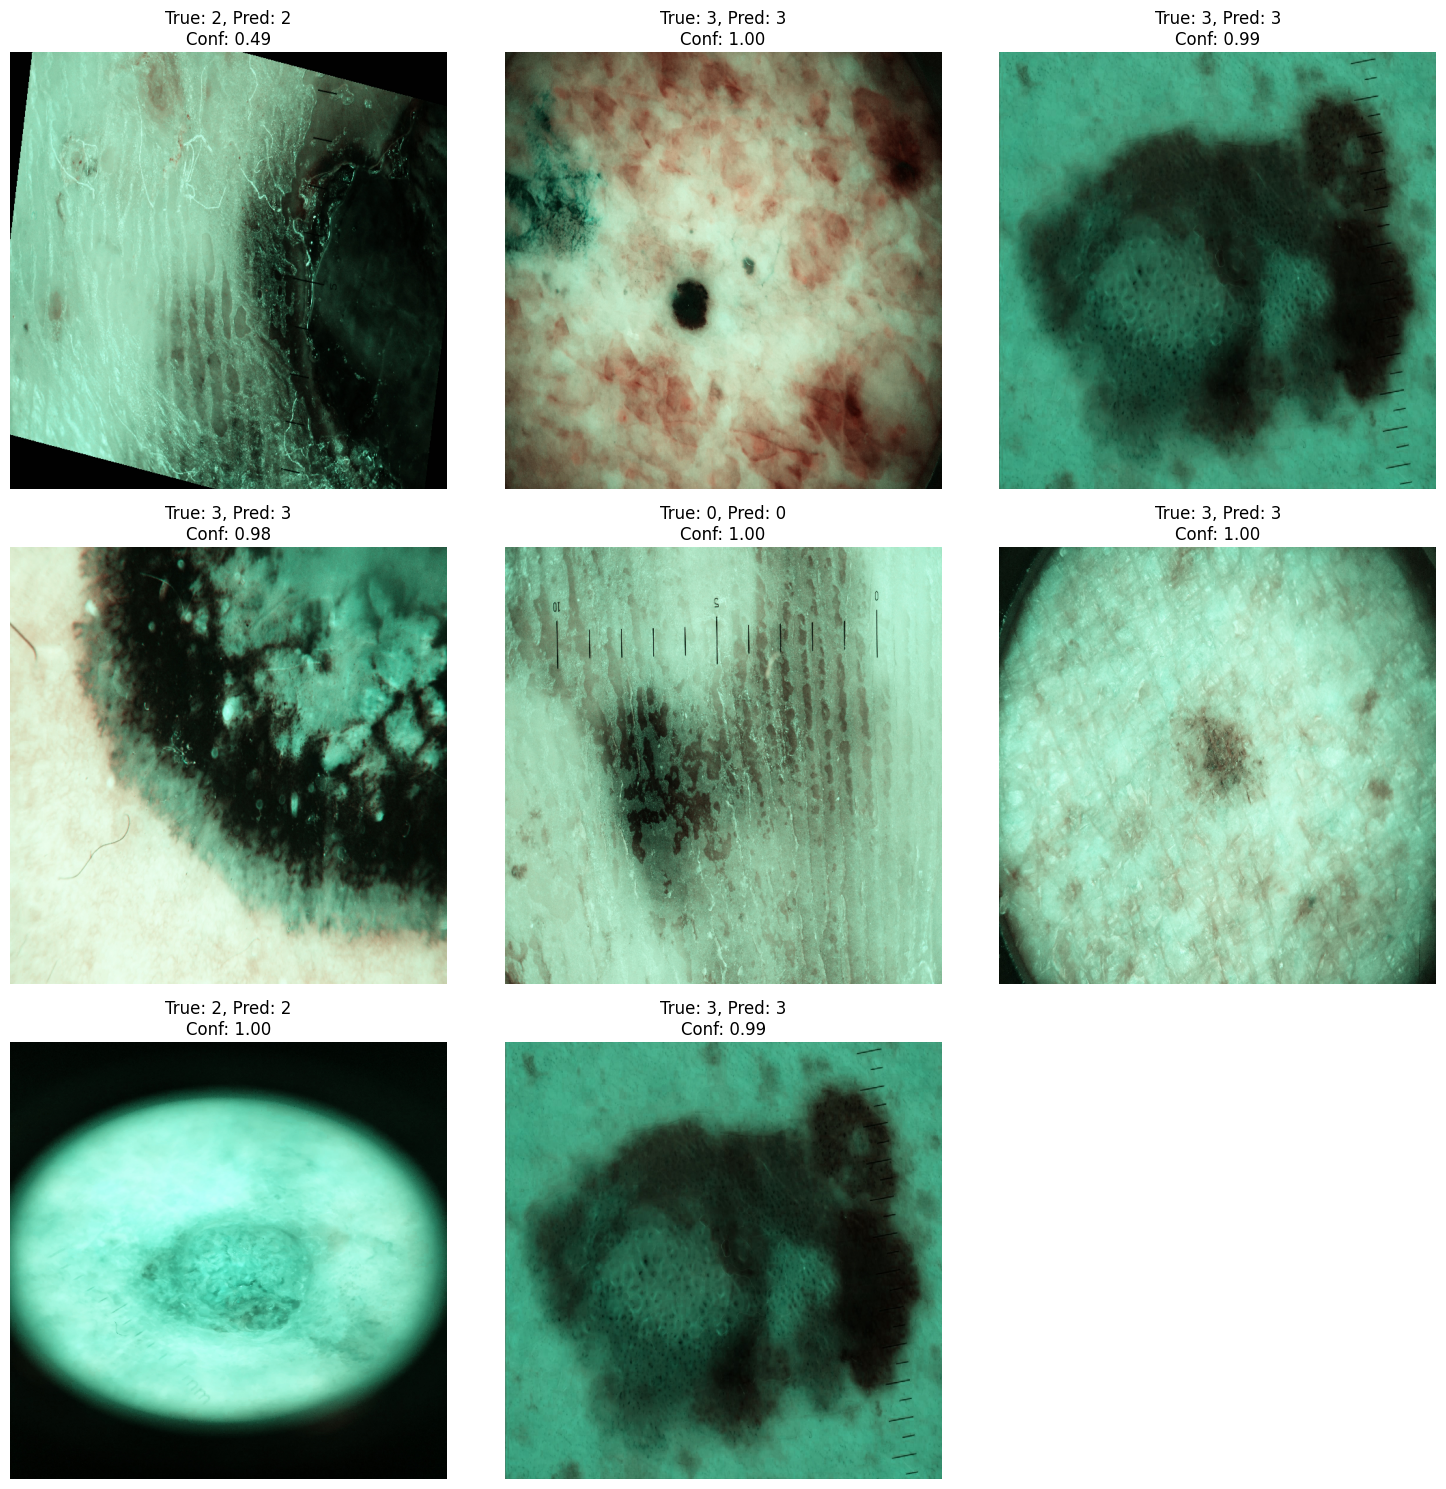

In [6]:
import numpy as np
import joblib
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix


test_dir = '/kaggle/input/test-save'
model_path = '/kaggle/working/xgboost_SAVEefficientnetb0_model.joblib'


xgb_model = joblib.load(model_path)
print(f"Model loaded from {model_path}")


datagen = ImageDataGenerator(rescale=1./255)
test_generator = datagen.flow_from_directory(
    test_dir,
    target_size=(640, 640),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)


base_model = tf.keras.applications.EfficientNetB0(weights='imagenet', include_top=False, pooling='avg')

def extract_features(generator):
    features = base_model.predict(generator)
    labels = generator.classes
    return features, labels

test_features, test_labels = extract_features(test_generator)


test_predictions = xgb_model.predict(test_features)
pred_proba = xgb_model.predict_proba(test_features)


print("Test Classification Report:")
print(classification_report(test_labels, test_predictions))


test_cm = confusion_matrix(test_labels, test_predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(test_cm, annot=True, fmt="d", cmap="Greens", 
            xticklabels=test_generator.class_indices.keys(), 
            yticklabels=test_generator.class_indices.keys())
plt.title("Test Confusion Matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

import matplotlib.pyplot as plt
import numpy as np
import os
from tensorflow.keras.preprocessing import image


num_images = 8
indices = np.random.choice(len(predictions_df), num_images, replace=False)

plt.figure(figsize=(15, 15))
for i, idx in enumerate(indices):
    img_path = os.path.join(test_dir, predictions_df.loc[idx, 'Image'])
    img = image.load_img(img_path, target_size=(640, 640))
    img_array = image.img_to_array(img) / 255.0  
    
   
    true_label = predictions_df.loc[idx, 'True Label']
    predicted_label = predictions_df.loc[idx, 'Predicted Label']
    confidence = predictions_df.loc[idx, 'Confidence']

    plt.subplot(3, 3, i + 1)
    plt.imshow(img_array)
    plt.axis('off')
    plt.title(f"True: {true_label}, Pred: {predicted_label}\nConf: {confidence:.2f}")

plt.tight_layout()
plt.show()


Found 3028 images belonging to 4 classes.
Found 280 images belonging to 4 classes.
Found 88 images belonging to 4 classes.


/opt/conda/lib/python3.10/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


95/95 ━━━━━━━━━━━━━━━━━━━━ 204s 2s/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step
Validation Classification Report:
              precision    recall  f1-score   support

           0       0.93      1.00      0.96       116
           1       0.77      0.77      0.77        44
           2       1.00      0.80      0.89        40
           3       0.86      0.85      0.86        80

    accuracy                           0.89       280
   macro avg       0.89      0.86      0.87       280
weighted avg       0.89      0.89      0.89       280



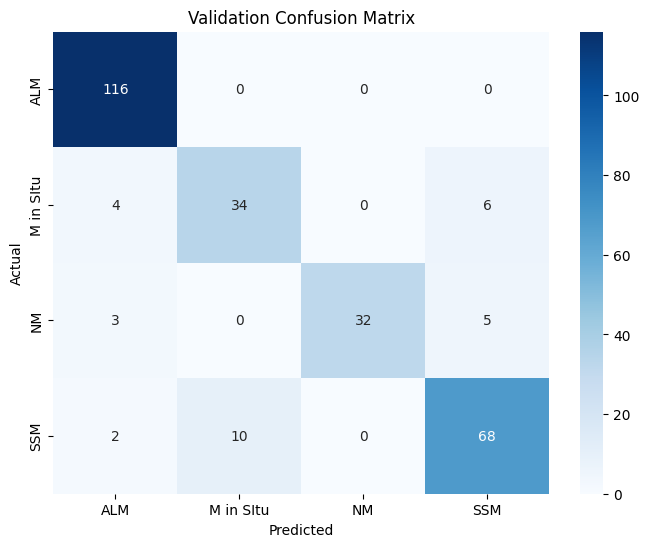

Test Classification Report:
              precision    recall  f1-score   support

           0       0.79      1.00      0.88        26
           1       0.75      0.62      0.68        24
           2       0.75      0.67      0.71        18
           3       0.63      0.60      0.62        20

    accuracy                           0.74        88
   macro avg       0.73      0.72      0.72        88
weighted avg       0.73      0.74      0.73        88



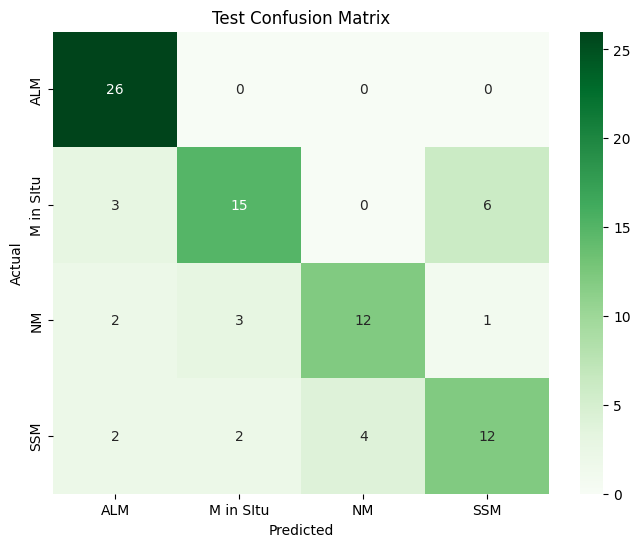

XGBoost model saved to xgboost_RGBefficientnetb0_model.joblib
Predictions saved to test_predictions_xgb_efficientnetb0.csv
Predictions saved to test_predictions_xgb_efficientnetb0.csv


In [11]:
import numpy as np
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import pandas as pd


train_dir = '/kaggle/input/train-rgb'
val_dir = '/kaggle/input/valid-rgb'
test_dir = '/kaggle/input/test-rgb'


model_path = 'xgboost_RGBefficientnetb0_model.joblib'


base_model = tf.keras.applications.EfficientNetB0(weights='imagenet', include_top=False, pooling='avg')

datagen = ImageDataGenerator(rescale=1./255)

train_generator = datagen.flow_from_directory(
    train_dir,
    target_size=(640, 640),
    batch_size=32,
    class_mode='binary',  
    shuffle=False
)

val_generator = datagen.flow_from_directory(
    val_dir,
    target_size=(640, 640),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

test_generator = datagen.flow_from_directory(
    test_dir,
    target_size=(640, 640),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

def extract_features(generator):
    features = base_model.predict(generator)
    labels = generator.classes
    return features, labels


train_features, train_labels = extract_features(train_generator)
val_features, val_labels = extract_features(val_generator)
test_features, test_labels = extract_features(test_generator)


xgb_model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='mlogloss')
xgb_model.fit(train_features, train_labels)


val_predictions = xgb_model.predict(val_features)
print("Validation Classification Report:")
print(classification_report(val_labels, val_predictions))

val_cm = confusion_matrix(val_labels, val_predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(val_cm, annot=True, fmt="d", cmap="Blues", xticklabels=train_generator.class_indices.keys(), yticklabels=train_generator.class_indices.keys())
plt.title("Validation Confusion Matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()


test_predictions = xgb_model.predict(test_features)
print("Test Classification Report:")
print(classification_report(test_labels, test_predictions))


test_cm = confusion_matrix(test_labels, test_predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(test_cm, annot=True, fmt="d", cmap="Greens", xticklabels=test_generator.class_indices.keys(), yticklabels=test_generator.class_indices.keys())
plt.title("Test Confusion Matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()


joblib.dump(xgb_model, model_path)
print(f"XGBoost model saved to {model_path}")

pred_proba = xgb_model.predict_proba(test_features)
predictions_df = pd.DataFrame({
    'Image': test_generator.filenames,
    'True Label': test_labels,  
    'Predicted Label': test_predictions,  
    'Confidence': [max(proba) for proba in pred_proba]
})
predictions_df.to_csv("test_predictions_xgb_efficientnetb0.csv", index=False)
print("Predictions saved to test_predictions_xgb_efficientnetb0.csv")

predictions_df.to_csv("test_predictions_xgb_efficientnetb0.csv", index=False)
print("Predictions saved to test_predictions_xgb_efficientnetb0.csv")


Model loaded from /kaggle/working/xgboost_RGBefficientnetb0_model.joblib
Found 88 images belonging to 4 classes.


/opt/conda/lib/python3.10/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


3/3 ━━━━━━━━━━━━━━━━━━━━ 15s 3s/step 
Test Classification Report:
              precision    recall  f1-score   support

           0       0.79      1.00      0.88        26
           1       0.75      0.62      0.68        24
           2       0.75      0.67      0.71        18
           3       0.63      0.60      0.62        20

    accuracy                           0.74        88
   macro avg       0.73      0.72      0.72        88
weighted avg       0.73      0.74      0.73        88



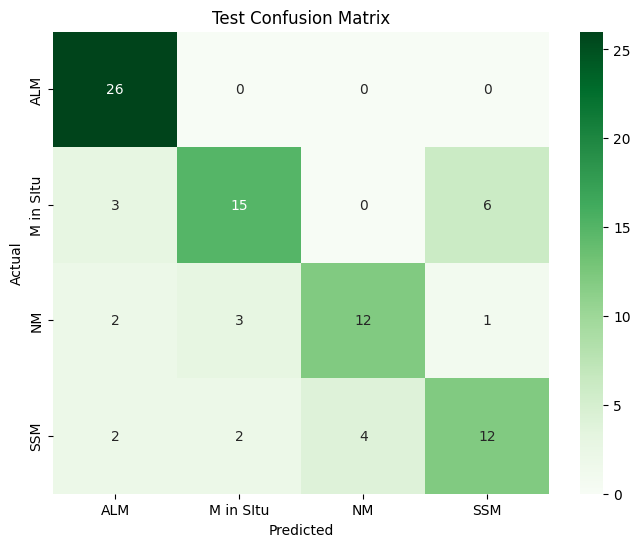

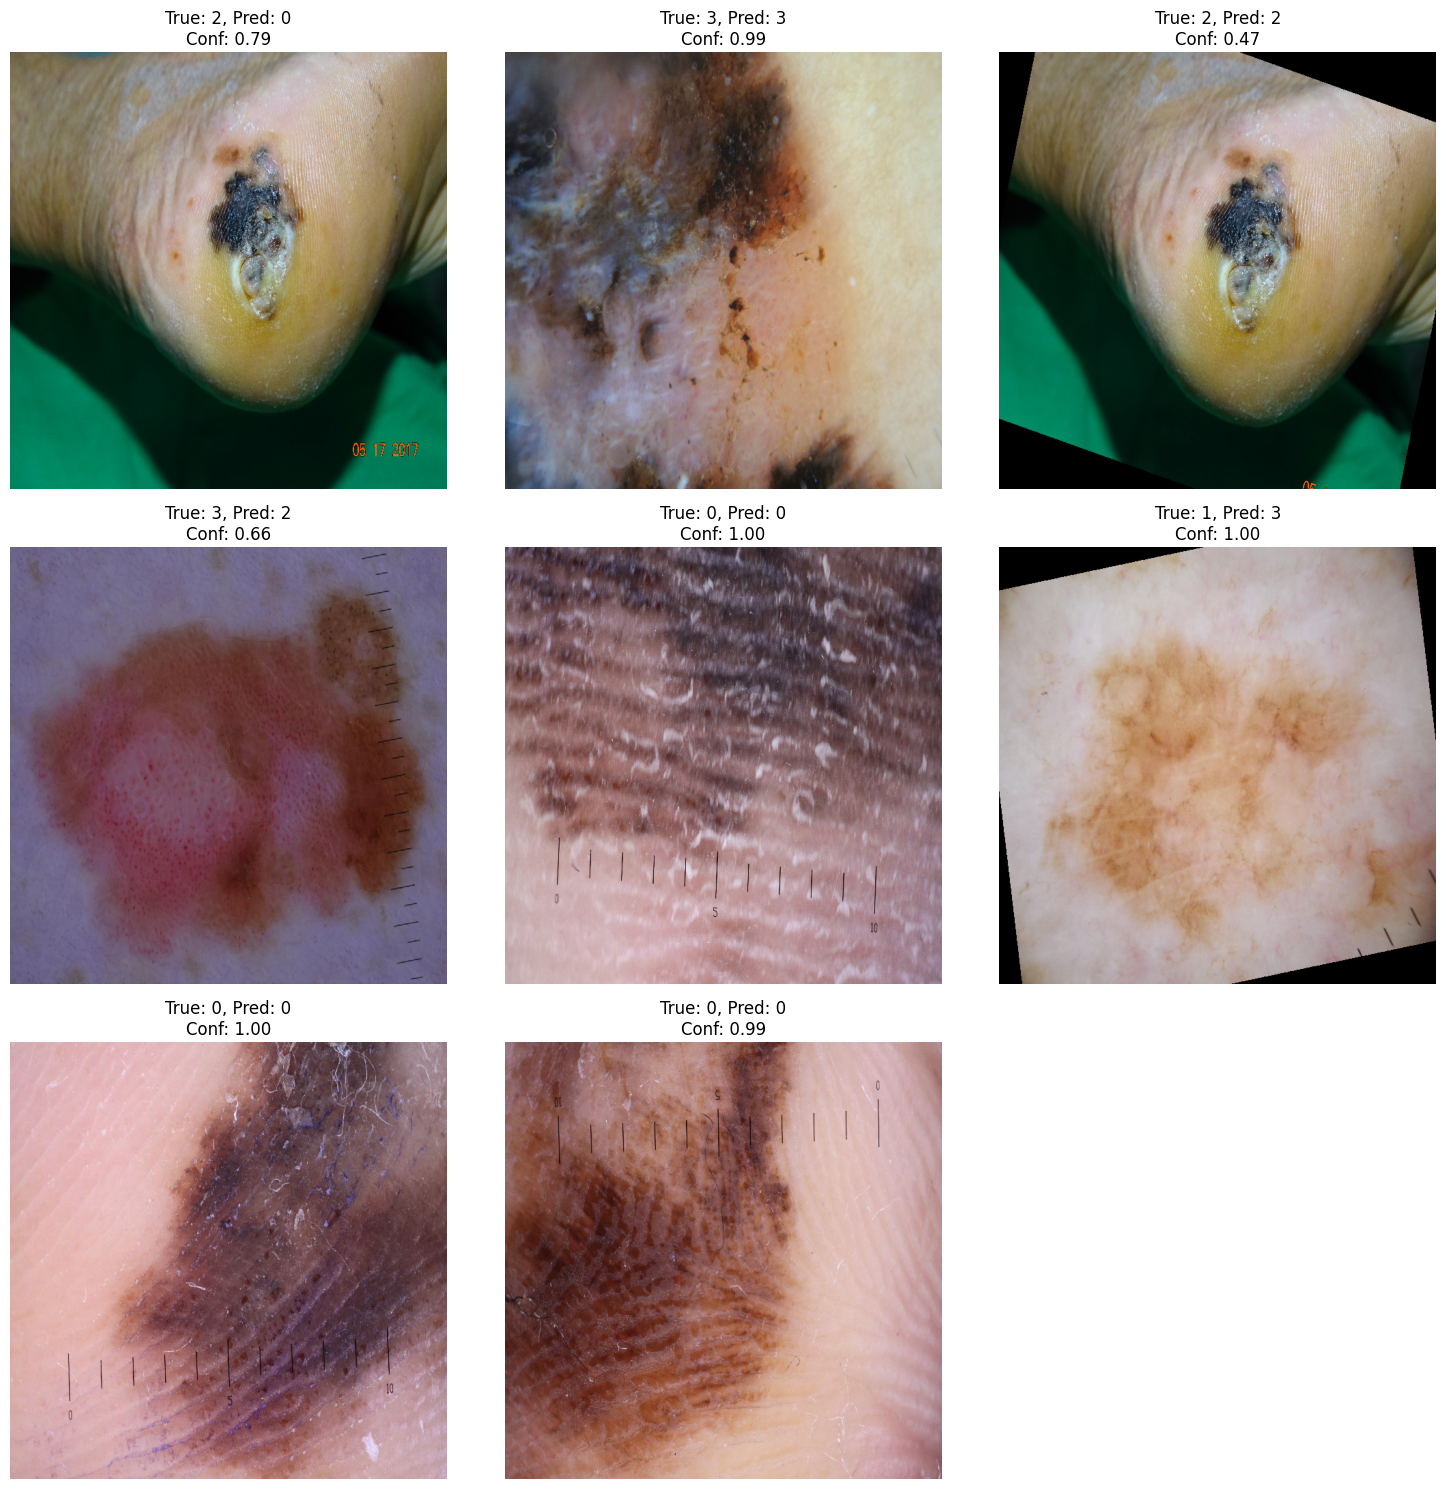

In [12]:
import numpy as np
import joblib
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix


test_dir = '/kaggle/input/test-rgb'
model_path = '/kaggle/working/xgboost_RGBefficientnetb0_model.joblib'


xgb_model = joblib.load(model_path)
print(f"Model loaded from {model_path}")

# ImageDataGenerator for test data (adjust if needed)
datagen = ImageDataGenerator(rescale=1./255)
test_generator = datagen.flow_from_directory(
    test_dir,
    target_size=(640, 640),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

# Extract test features using the same EfficientNetB0 model
base_model = tf.keras.applications.EfficientNetB0(weights='imagenet', include_top=False, pooling='avg')

def extract_features(generator):
    features = base_model.predict(generator)
    labels = generator.classes
    return features, labels

test_features, test_labels = extract_features(test_generator)

# Predict using the loaded XGBoost model
test_predictions = xgb_model.predict(test_features)
pred_proba = xgb_model.predict_proba(test_features)

# Display classification report
print("Test Classification Report:")
print(classification_report(test_labels, test_predictions))

# Generate and display confusion matrix
test_cm = confusion_matrix(test_labels, test_predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(test_cm, annot=True, fmt="d", cmap="Greens", 
            xticklabels=test_generator.class_indices.keys(), 
            yticklabels=test_generator.class_indices.keys())
plt.title("Test Confusion Matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

import matplotlib.pyplot as plt
import numpy as np
import os
from tensorflow.keras.preprocessing import image

# Number of images to display
num_images = 8
indices = np.random.choice(len(predictions_df), num_images, replace=False)

plt.figure(figsize=(15, 15))
for i, idx in enumerate(indices):
    img_path = os.path.join(test_dir, predictions_df.loc[idx, 'Image'])
    img = image.load_img(img_path, target_size=(640, 640))
    img_array = image.img_to_array(img) / 255.0  # Scale the image for display
    
    # Get the true label, predicted label, and confidence for the image
    true_label = predictions_df.loc[idx, 'True Label']
    predicted_label = predictions_df.loc[idx, 'Predicted Label']
    confidence = predictions_df.loc[idx, 'Confidence']

    plt.subplot(3, 3, i + 1)
    plt.imshow(img_array)
    plt.axis('off')
    plt.title(f"True: {true_label}, Pred: {predicted_label}\nConf: {confidence:.2f}")

plt.tight_layout()
plt.show()
